# E12.5 mouse embryo: Visium HD communication for PLA-assayed LR pairs

A1 and D1 are two Visium HD sections, each paired with adjacent PLA sections. This tutorial provides optional RNA-only training, displays the original H&E and PLA images, and maps the five assayed LR pairs.

Training is commented out by default. **Run All** uses saved CellSTIC results and recomputes the analyses below. Figures and tables are saved alongside the existing model results under `DATA / "cellstic"`. Run All does not train or modify the saved model.

## 1. Set up the dataset

Start Jupyter from this repository. Use the environment in `environment.yml` and supply the assembled inputs and saved results at the paths below.

In [1]:
from pathlib import Path
import sys
import json
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline/cellstic.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from pipeline.analysis import Analysis
from utils.analysis.result_io import load_result, lr_matrices, channel_keys
from utils.analysis import dataset_analysis as da
%matplotlib inline
plt.style.use("default")
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

<conda-env>/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA = ROOT / "paper/data/e12_mouse_embryo"
SAMPLES = ["A1", "D1"]
RUN_ROOT = DATA / "cellstic"
OUTPUT = DATA / "cellstic"
OUTPUT.mkdir(parents=True, exist_ok=True)

## 2. Train both Visium HD samples (optional)

Each sample has its own assayed LR panel in the input metadata. These large sections require substantial memory and benefit from a GPU. The saved fits skipped final domain clustering; this example uses the same option and retains the supplied Space Ranger graph clusters for regional summaries.

In [3]:
# from model.train import get_cellstic_config
# from pipeline.cellstic import run_cellstic
# from utils.tools import CellChatDBLoader
# config = get_cellstic_config("mouse_embryo")
# cellchat = CellChatDBLoader().get_ligand_receptor_map("mouse")

In [4]:
# for sample in SAMPLES:
#     rna = ad.read_h5ad(DATA / "h5ad" / f"{sample}.h5ad")
#     pairs = rna.uns["pla_pairs"]
#     lr_map = {row.ligand: [row.receptor] for row in pairs.itertuples(index=False)}
#     run_cellstic([rna], config, modality_types=["rna"], ligand_receptor_map=lr_map,
#                  cell_chat_db=cellchat, output_path=RUN_ROOT / sample,
#                  skip_spatial_domain_prediction=True)


## 3. Load the two results and their LR panels

The analysis reader leaves the full RNA matrices and microscopy images on disk. Sample-specific LR pairs come from the saved PLA metadata.

In [5]:
results = {sample: load_result(RUN_ROOT / sample / "out/out.h5ad") for sample in SAMPLES}
display(pd.DataFrame([{"sample": sample, "16-µm bins": result.n_obs,
                       "LR pairs": ", ".join(lr_matrices(result))} for sample, result in results.items()]))

,sample,16-µm bins,LR pairs
0,A1,85017,"Dll1:Notch1, Fgf8:Fgfr1"
1,D1,93248,"Efna3:Epha5, Igf2:Igf2r, Spp1:Cd44"


## 4. Inspect the original H&E tissue images

A1 and D1 are displayed side by side using the H&E images and physical scale factors stored in the assembled input data. The views crop around the complete tissue outlines with equal physical spans and 1-mm scale bars. No model-derived values are overlaid.

A1: 85,017 spatial bins


D1: 93,248 spatial bins


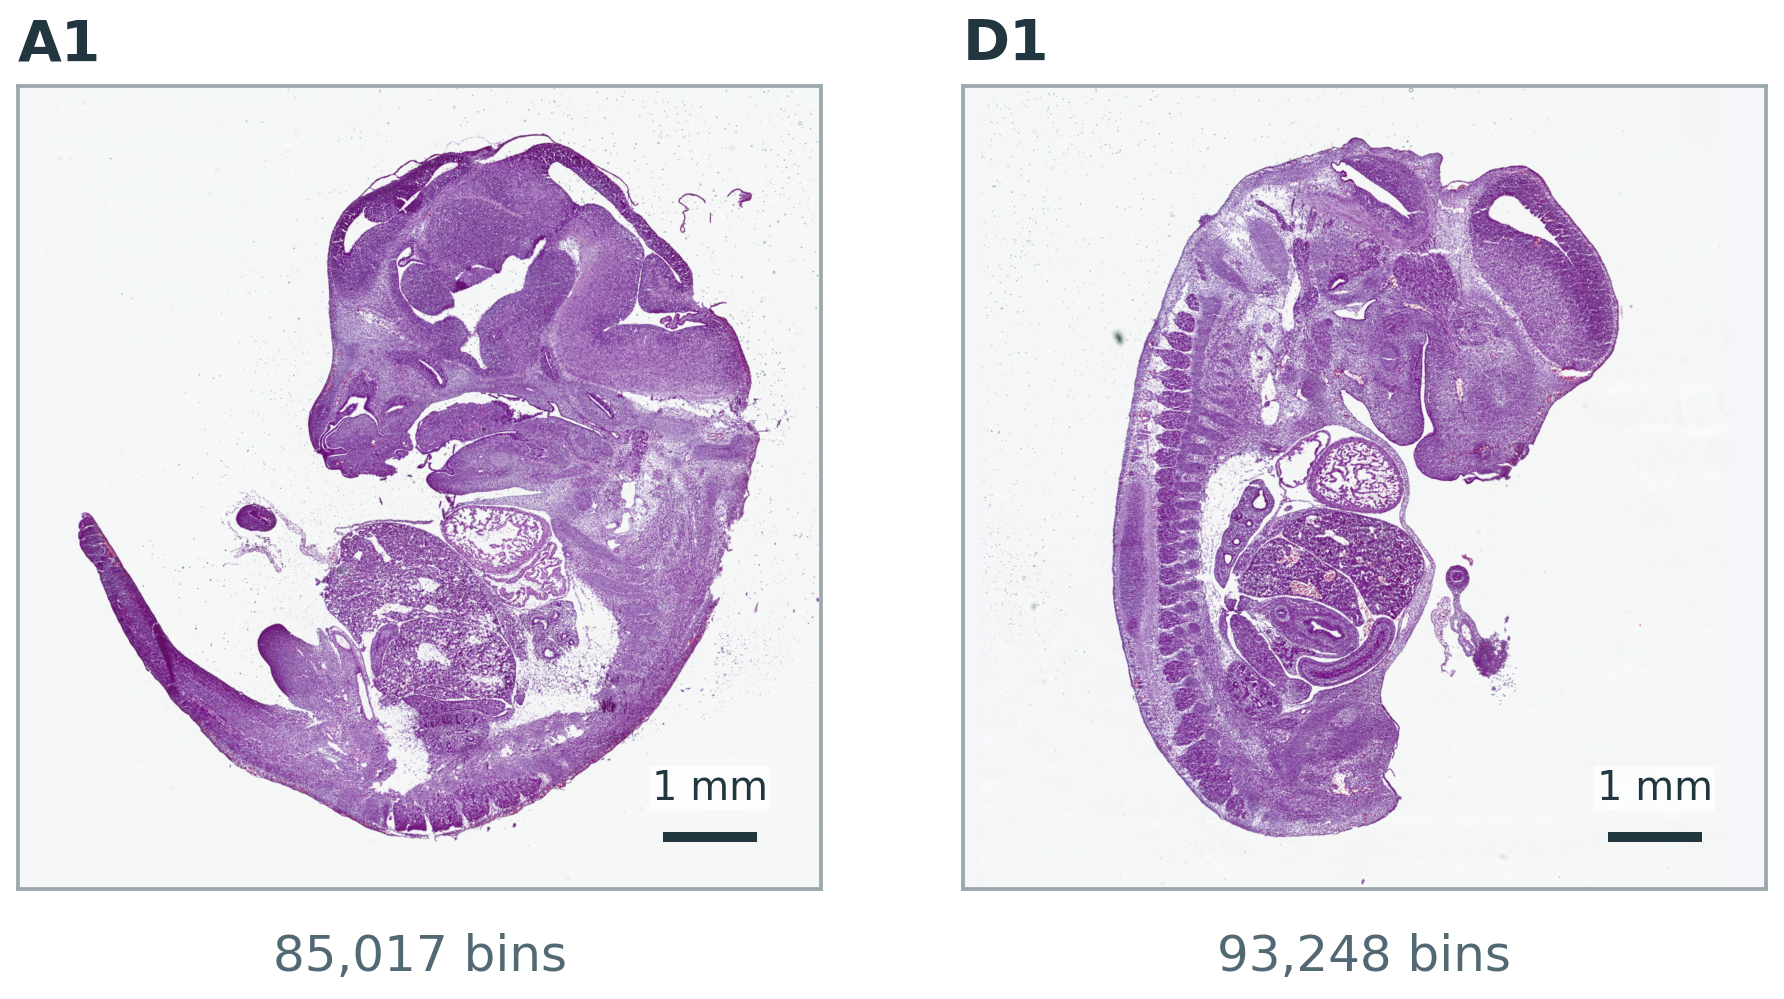

In [6]:
from utils.analysis import embryo_visualization as ev
ev.e12_histology(DATA, OUTPUT / "images/histology")

## 5. Inspect the five original PLA images

The five native PLA images are shown in the same LR-pair order as the predictions below. These are adjacent sections, shown in their original orientations without registration. Each image is reduced to a preview and displayed from zero to its own 99.5th intensity percentile; color brightness is therefore not an absolute comparison across assays. Adjacent sections do not provide bin-matched ground truth.

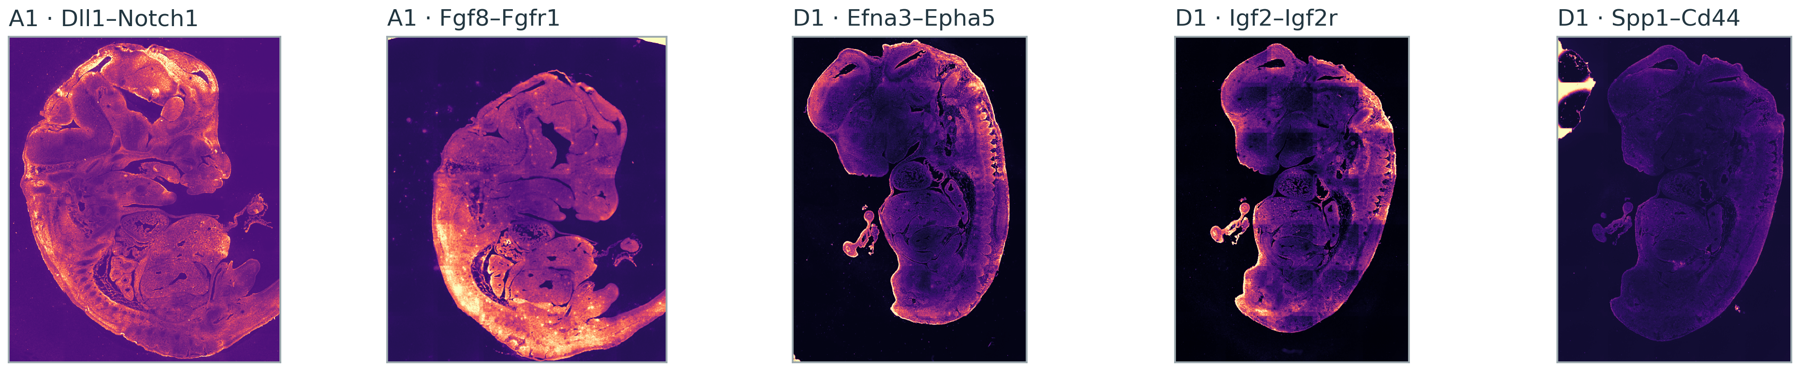

In [7]:
ev.e12_raw_pla(DATA, results, OUTPUT / "images/pla")

## 6. Map all five PLA-associated LR predictions

Incoming scores are ranked among positive receivers separately for each channel. Zero receivers remain zero. All measured bins enter the calculation; the five maps use the same 0–1 color scale.

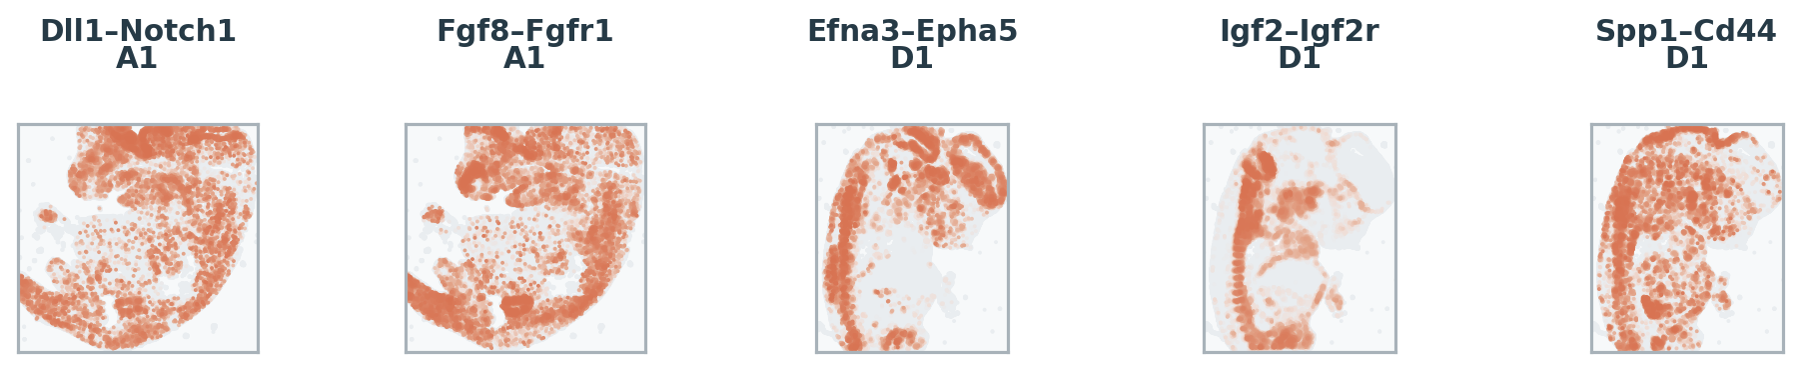

In [8]:
ev.e12_predictions(results, OUTPUT / "ccc")